In [1]:
import pandas as pd

In [5]:
from google.colab import files


In [6]:
uploaded = files.upload()

Saving titanic_dataset.csv to titanic_dataset.csv


In [7]:
train = pd.read_csv("titanic_dataset.csv")

In [8]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
train = train.set_index("PassengerId")

In [10]:
train.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
train.shape

(891, 11)

In [12]:
train.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket',
       'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [13]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [14]:
train.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:
train.isnull().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


In [16]:
train.isnull().sum()[train.isnull().sum() > 0]

,0
Age,177
Cabin,687
Embarked,2


In [17]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [18]:
train['Age'] = train['Age'].fillna(train['Age'].median())

In [19]:
train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])

In [20]:
train['Embarked'].mode()[0]

'S'

In [21]:
train['Cabin'] = train['Cabin'].fillna('Unknown')

In [22]:
train.isnull().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,0


In [23]:
train.isnull().sum().sum()

np.int64(0)

In [24]:
import matplotlib.pyplot as plt

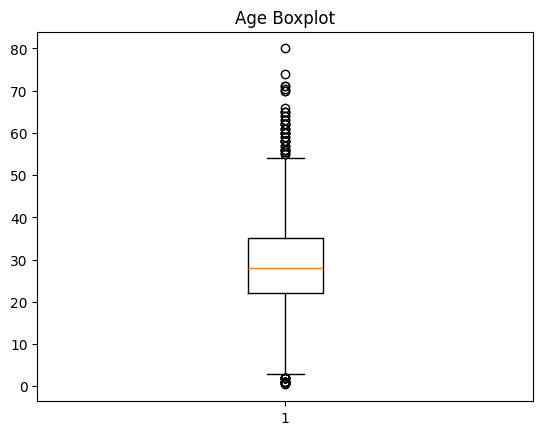

In [25]:
plt.boxplot(train['Age'])
plt.title('Age Boxplot')
plt.show()

In [26]:
Q1 = train['Age'].quantile(0.25)
Q3 = train['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 22.0
Q3: 35.0
IQR: 13.0
Lower limit: 2.5
Upper limit: 54.5


In [27]:
age_outliers = train[(train['Age'] < lower_limit) | (train['Age'] > upper_limit)]

print("Number of Age outliers:", len(age_outliers))

Number of Age outliers: 66


In [28]:
train['Age'] = train['Age'].clip(lower=lower_limit, upper=upper_limit)

In [29]:
Q1 = train['Fare'].quantile(0.25)
Q3 = train['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Lower limit: -26.724
Upper limit: 65.6344


In [30]:
fare_outliers = train[(train['Fare'] < lower_limit) | (train['Fare'] > upper_limit)]

print("Number of Fare outliers:", len(fare_outliers))

Number of Fare outliers: 116


In [31]:
train['Fare'] = train['Fare'].clip(lower=lower_limit, upper=upper_limit)

In [32]:
Q1 = train['SibSp'].quantile(0.25)
Q3 = train['SibSp'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower limit: -1.5
Upper limit: 2.5


In [33]:
sibsp_outliers = train[(train['SibSp'] < lower_limit) | (train['SibSp'] > upper_limit)]

print("Number of SibSp outliers:", len(sibsp_outliers))

Number of SibSp outliers: 46


In [34]:
train['SibSp'] = train['SibSp'].clip(lower=lower_limit, upper=upper_limit)

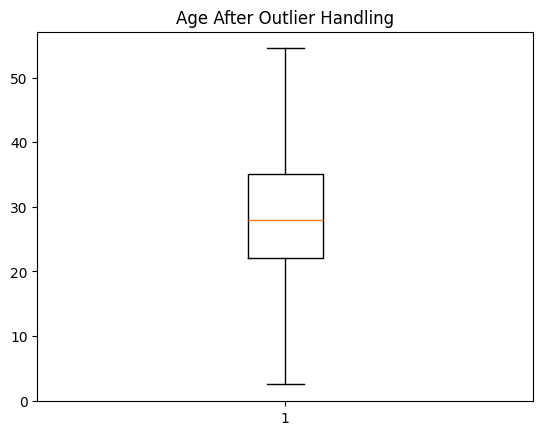

In [35]:
plt.boxplot(train['Age'])
plt.title('Age After Outlier Handling')
plt.show()

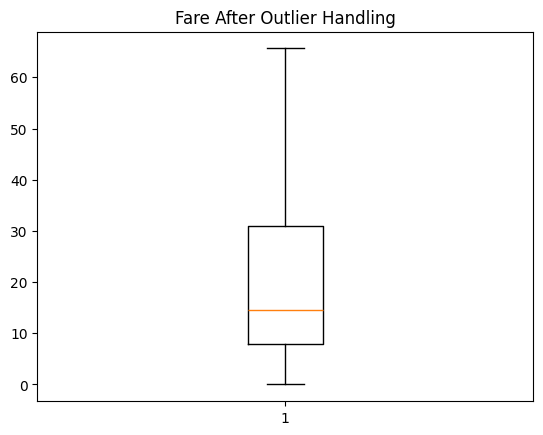

In [36]:
plt.boxplot(train['Fare'])
plt.title('Fare After Outlier Handling')
plt.show()

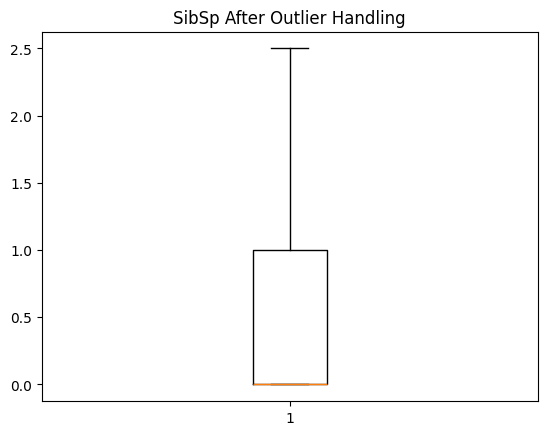

In [37]:
plt.boxplot(train['SibSp'])
plt.title('SibSp After Outlier Handling')
plt.show()

In [38]:
train.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket',
       'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [39]:
X = train.drop('Survived', axis=1)
y = train['Survived']

In [40]:
X = X.drop(['Name', 'Ticket', 'Cabin'], axis=1)

In [41]:
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

In [42]:
X.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
PassengerId,,,,,,,,
1,3,22.0,1.0,0,7.2500,True,False,True
2,1,38.0,1.0,0,65.6344,False,False,False
3,3,26.0,0.0,0,7.9250,False,False,True
4,1,35.0,1.0,0,53.1000,False,False,True
5,3,35.0,0.0,0,8.0500,True,False,True


In [43]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      891 non-null    int64  
 1   Age         891 non-null    float64
 2   SibSp       891 non-null    float64
 3   Parch       891 non-null    int64  
 4   Fare        891 non-null    float64
 5   Sex_male    891 non-null    bool   
 6   Embarked_Q  891 non-null    bool   
 7   Embarked_S  891 non-null    bool   
dtypes: bool(3), float64(3), int64(2)
memory usage: 44.4 KB


In [44]:
from sklearn.model_selection import train_test_split

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [46]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 8)
X_test: (179, 8)
y_train: (712,)
y_test: (179,)


In [47]:
X = train.drop('Survived', axis=1)
y = train['Survived']

In [48]:
X = X.drop(['Name', 'Ticket', 'Cabin'], axis=1)

In [49]:
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [51]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((712, 8), (179, 8), (712,), (179,))

In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
model = LogisticRegression(max_iter=1000)

In [54]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [55]:
y_pred = model.predict(X_test)

In [56]:
from sklearn.metrics import accuracy_score

In [57]:
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.7988826815642458


In [58]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[89 16]
 [20 54]]


In [59]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [60]:
logistic_accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression:", logistic_accuracy)

Logistic Regression: 0.7988826815642458


In [61]:
from sklearn.tree import DecisionTreeClassifier

In [62]:
dt_model = DecisionTreeClassifier(random_state=42)

In [63]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [64]:
dt_pred = dt_model.predict(X_test)

In [65]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7821229050279329


In [66]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.81      0.82      0.82       105
           1       0.74      0.73      0.73        74

    accuracy                           0.78       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



In [67]:
print(confusion_matrix(y_test, dt_pred))

[[86 19]
 [20 54]]


In [68]:
from sklearn.ensemble import RandomForestClassifier

In [69]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [70]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [71]:
rf_pred = rf_model.predict(X_test)

In [72]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8156424581005587


In [73]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       105
           1       0.80      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.81      0.82      0.81       179



In [74]:
print(confusion_matrix(y_test, rf_pred))

[[91 14]
 [19 55]]


In [75]:
from sklearn.neighbors import KNeighborsClassifier

In [76]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [77]:
knn_model.fit(X_train, y_train)

KNeighborsClassifier()

In [78]:
knn_pred = knn_model.predict(X_test)

In [79]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.7039106145251397


In [80]:
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.72      0.80      0.76       105
           1       0.67      0.57      0.61        74

    accuracy                           0.70       179
   macro avg       0.70      0.68      0.69       179
weighted avg       0.70      0.70      0.70       179



In [81]:
print(confusion_matrix(y_test, knn_pred))

[[84 21]
 [32 42]]


In [82]:
from sklearn.svm import SVC

In [83]:
svm_model = SVC()

In [84]:
svm_model.fit(X_train, y_train)

SVC()

In [85]:
svm_pred = svm_model.predict(X_test)

In [86]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.6703910614525139


In [87]:
print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.66      0.92      0.77       105
           1       0.74      0.31      0.44        74

    accuracy                           0.67       179
   macro avg       0.70      0.62      0.60       179
weighted avg       0.69      0.67      0.63       179



In [88]:
print(confusion_matrix(y_test, svm_pred))

[[97  8]
 [51 23]]


In [89]:
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'SVM'
    ],
    'Accuracy': [
        logistic_accuracy,
        dt_accuracy,
        rf_accuracy,
        knn_accuracy,
        svm_accuracy
    ]
})

model_results

,Model,Accuracy
0,Logistic Regression,0.798883
1,Decision Tree,0.782123
2,Random Forest,0.815642
3,KNN,0.703911
4,SVM,0.670391


In [90]:
model_results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,Random Forest,0.815642
0,Logistic Regression,0.798883
1,Decision Tree,0.782123
3,KNN,0.703911
4,SVM,0.670391


In [91]:
best_model = model_results.loc[model_results['Accuracy'].idxmax()]

print("Best Model:", best_model['Model'])
print("Best Accuracy:", best_model['Accuracy'])

Best Model: Random Forest
Best Accuracy: 0.8156424581005587


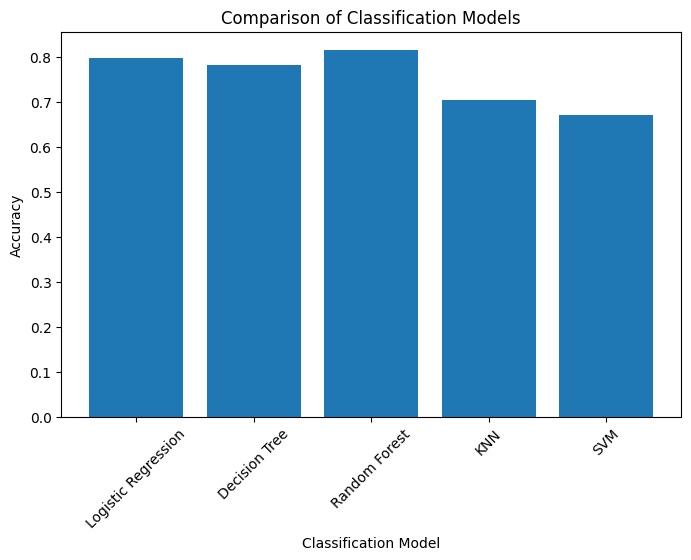

In [92]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(model_results['Model'], model_results['Accuracy'])

plt.xlabel('Classification Model')
plt.ylabel('Accuracy')
plt.title('Comparison of Classification Models')

plt.xticks(rotation=45)
plt.show()

In [93]:
model_results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,Random Forest,0.815642
0,Logistic Regression,0.798883
1,Decision Tree,0.782123
3,KNN,0.703911
4,SVM,0.670391
